Using device: mps


/opt/homebrew/anaconda3/lib/python3.12/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


CLIPTextModel LOAD REPORT from: /Users/siya/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


StableDiffusionSafetyChecker LOAD REPORT from: /Users/siya/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


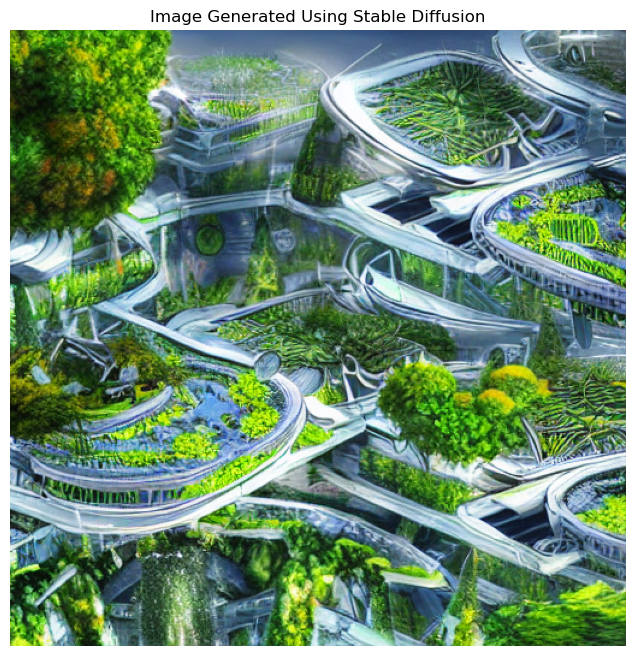

Image saved as generated_image.png


In [1]:
import torch
import matplotlib.pyplot as plt
from diffusers import StableDiffusionPipeline

# Automatically select GPU or CPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

print("Using device:", device)

# Load Stable Diffusion model
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=dtype
)

pipe = pipe.to(device)
pipe.enable_attention_slicing()

# Text prompt
prompt = "A beautiful futuristic city with green gardens, modern buildings, mountains, realistic digital art"

# Generate image
image = pipe(
    prompt,
    num_inference_steps=15,
    guidance_scale=7.5
).images[0]

# Display image
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Image Generated Using Stable Diffusion")
plt.show()

# Save image
image.save("generated_image.png")
print("Image saved as generated_image.png")